# Notebook 1. Whole Brain Analysis

In [1]:
# Work from this notebook's folder (content/), also when the notebook is executed from the project root
# (myst build --execute, NeuroLibre), so the local modules (helpers, stats_test, ...) and ../data/ resolve.
import os
import sys

if os.path.isdir("content") and not os.path.isfile("helpers.py"):
    os.chdir("content")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import numpy as np
from scipy.spatial import distance

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Setting text svg exports as exports
plt.rcParams['svg.fonttype'] = 'none'


In [3]:
# rpy2 configuration
#import rpy2.robjects as ro
from rpy2.robjects.packages import importr
#from rpy2.robjects import pandas2ri
#from rpy2.robjects.conversion import localconverter

try:
    effectsize = importr('effectsize')
    marginaleffects = importr('marginaleffects')
    car = importr('car')
    print("✅ All R dependencies are loaded and ready!")
except Exception as e:
    print(f"❌ Missing R package: {e}")

✅ All R dependencies are loaded and ready!


In [4]:
# Import auxiliary functions bundled in this notebook
import ancova_assumptions as aa
import stats_test as st
import helpers


The next flag creates static figures that were used as a base for paper static version. Saved in static folder. If you want to create them again, set this variable to True. Otherwise, set it to False.

In [5]:
# Static (matplotlib/seaborn) figure versions for the Word/PDF/LaTeX exports and the journal figures.
# Written to static/figures/ only when STATIC_FIGURE_FORMATS is set (pixi tasks static-figures-png/-pdf/-svg,
# export-docx, export-tex). A plain `pixi run run-notebooks` does not write them.
create_Static_figures = bool(helpers.STATIC_FIGURE_FORMATS)

# This color pallet matches plotly figures with seaborn defaults.
color_palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]

## Load data

In [6]:
df = pd.read_csv(helpers.data_path("hyades_wholeBrain_ROIs.csv"))

In [7]:
# Exclusion list obtained from QC the segemntation and registration of the anatomical scans. Participants with a QC level of 0 were excluded from the analyses.
exclusion_list = pd.read_csv(helpers.data_path("exclusion_list.csv")) 
print(exclusion_list)
exclusion_list = exclusion_list["participant_id"].to_list()

  participant_id                                             reason
0        sub-021  HippUnfold segmentation with a small leak arti...
1        sub-024  HippUnfold segmentation slightly failed: SRLM ...
2        sub-035  HippUnfold segmentation failed with an artifac...
3        sub-045  HippUnfold segmentation slightly failed with s...
4        sub-049  HippUnfold segmentation failed with subiculum ...
5        sub-051  HippUnfold segmentation struggled with multipl...
6        sub-057  HippUnfold segmentation failed with small leak...


## Wrangling

In [8]:
# rename column from dataframe (just for stylec onsitency with paper)
df = df.rename(columns={'D_dki': 'MD'})

# normalized_volume is the ROI volume as a fraction of total intracranial volume (TIV); express it as % of TIV
# (same units as the hippocampal subfield volumes; F statistics, effect sizes and p-values are unaffected)
df['normalized_volume'] = df['normalized_volume'] * 100

In [9]:
# Drop subjects with other diagnosis than dementia
nonDemGroups = ['PDD','PSP','VCI','PD','Conc','aMCI','TBD']
df = df.query("group != @nonDemGroups")

In [10]:
# Drop subjects in the exclusion list
df = df.query("participant_id != @exclusion_list")

In [11]:
# Define the desired order of categories
group_order = ['HC', 'LBD', 'FTD', 'AD']

# Convert to ordered categorical type (the data files code healthy controls as 'Control'; the paper uses HC)
df['group'] = df['group'].replace({'Control': 'HC'})
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

# harmonize color palette
group_colors = dict(zip(group_order, color_palette))

In [12]:
# Drop "unkown" label structre 
df = df.query("structure != 'unknown'")

## Extract features to study

In [13]:
metadata = ["participant_id", "group", "age",'sex',"structure"]
#metrics = ["FA","D_uFA", "uFA", "Ki", "Vol_mm3_norm", "MTsat"]
metrics = ["FA","MD", "uFA", "Ki", "MTsat", "normalized_volume"]
df_brain_grouped = df[metadata + metrics]

In [14]:
# Define the order of the structures for plotting
structure_order = ["Parietal", "Frontal", "Temporal", "Occipital", "Cingulate", "Insula", "Hippocampus", "Amygdala"];

## 

## Mahallanobis distance by metric 

In [15]:
def mahalanobis_distance_byMetrics(df, group2compare = "HC", metrics=None):
    """
    Calculates the Mahalanobis distance of each subject to the distribution of the 'group2compare' group
    for each unique structure, using the columns in the metrics list.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing participant data.
    group2compare : str
        Column name for the group to compare with.
    metrics : str
        List of metrics to use to calculate the distance.

    Returns
    -------
    pd.DataFrame
        DataFrame with original data and the Mahalanobis distance for each structure to the group2compare group.
    """
    
    group_col='group'
    structure_col='structure'

    results = []
    
    for structure in df[structure_col].unique():
        df_struct = df[df[structure_col] == structure].copy()
        group2compare_df = df_struct[df_struct[group_col] == group2compare][metrics]
        if len(group2compare_df) < 2:
            continue  # Skip if not enough subjects for covariance
        group2compare_mean = group2compare_df.mean().values
        group2compare_cov = np.cov(group2compare_df, rowvar=False)
        group2compare_cov_inv = np.linalg.pinv(group2compare_cov)
        def compute_md(row):
            return distance.mahalanobis(row[metrics], group2compare_mean, group2compare_cov_inv)
        df_struct['mahalanobis_distance'] = df_struct.apply(compute_md, axis=1)
        
        results.append(df_struct)
    return pd.concat(results, ignore_index=True)


In [16]:
df_brain_grouped_mahallanobis = mahalanobis_distance_byMetrics(df_brain_grouped, group2compare = "HC", metrics=metrics)

In [17]:
#| label: notebook_fig_brainRois_MhD_boxplots
fig = px.box(
    df_brain_grouped_mahallanobis,
    x='structure',
    y='mahalanobis_distance',
    color='group',
    category_orders={
        'structure': structure_order,
        'group': group_order,
    },
    color_discrete_map=group_colors,
    labels={
        'structure': 'ROI',
        'mahalanobis_distance': 'Mahalanobis distance',
        'group': 'Group'
    },
)

# fig.update_layout(
#     width=2000,
#     height=600,
    
#     legend=dict(
#         orientation='v',
#         yanchor='middle', y=0.5,
#         xanchor='left', x=1.02,
#     ),
#     boxmode='group',
# )

fig

In [18]:
#| label: notebook_figStatic_brainRois_MhD_boxplots
if create_Static_figures:
    helpers.static_theme()
    fig, ax = plt.subplots(figsize=(helpers.TEXT_WIDTH_IN, 2.8))
    sns.boxplot(data=df_brain_grouped_mahallanobis, x='structure', y="mahalanobis_distance", hue="group",
                order=structure_order, palette=group_colors, ax=ax)
    sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1), title="Group", frameon=False)
    ax.set_xlabel("ROI")
    ax.set_ylabel("Mahalanobis distance")
    sns.despine(fig)
    fig.tight_layout()
    helpers.save_static_figure(fig, "fig_brainRois_MhD_boxplots")
    plt.close(fig)
    sns.set_theme()

### Plotting maha vs age

In [19]:
df_brain_grouped_mahallanobis_melted = pd.melt(df_brain_grouped_mahallanobis, id_vars=['participant_id','group','age','sex','structure'], value_vars='mahalanobis_distance',
        var_name='metric', value_name='value')

#df_brain_grouped_mahallanobis_melted

In [20]:
#| label: notebook_fig_brainRois_MhD_lmplots
fig = px.scatter(
    df_brain_grouped_mahallanobis_melted,
    x='age',
    y='value',
    color='group',
    facet_col='structure',
    facet_col_wrap=2,
    category_orders={
        'structure': structure_order,
        'group': group_order,
    },
    color_discrete_map=group_colors,
    trendline='ols',
    labels={
        'age': 'Age',
        'value': 'Value',
        'group': 'Group',
    },
)

# sharey=False equivalent: let each facet have its own y-axis range
fig.update_yaxes(matches=None, showticklabels=True)

# px.scatter + trendline creates a duplicate legend entry per group
# (one for points, one for the "...,trendline" line) — collapse to one
seen = set()
for trace in fig.data:
    base_name = trace.name.split(',')[0]
    trace.legendgroup = base_name
    if 'trendline' in trace.name:
        trace.showlegend = False
    elif base_name in seen:
        trace.showlegend = False
    else:
        trace.name = base_name
        seen.add(base_name)

# clean up facet titles ("structure=Hippocampus" -> "Hippocampus")
fig.for_each_annotation(lambda a: a.update(text=a.text.split('=')[-1]))

fig.update_layout(
    width=1100,
    height=1600,
    legend=dict(
        orientation='v',
        yanchor='middle', y=0.5,
        xanchor='left', x=1.02,
    ),
)

fig

In [21]:
#| label: notebook_figStatic_wholeBrain_ageMhD
if create_Static_figures:
    helpers.static_theme()
    # FacetGrid + regplot (same as lmplot) so the bootstrapped confidence bands can use a fixed seed
    p = sns.FacetGrid(df_brain_grouped_mahallanobis_melted, hue='group', palette=group_colors, col="structure",
                      col_wrap=4, col_order=structure_order, sharey=False, height=1.55, aspect=1.0)
    p.map_dataframe(sns.regplot, x='age', y='value', seed=0, scatter_kws={"s": 6})
    p.add_legend(title="Group")
    p.set_titles("{col_name}")
    p.set_axis_labels("Age (years)", "Mahalanobis distance")
    helpers.save_static_figure(p.figure, "fig_wholeBrain_ageMhD")
    plt.close(p.figure)
    sns.set_theme()

## Visualization of metrics by region

In [22]:
#| label: notebook_fig_brainRois_metrics_dropdown
qMRI_metrics = ["FA", "MD", "uFA", "Ki", "MTsat", "normalized_volume"]
default_metric = "uFA"
default_idx = qMRI_metrics.index(default_metric)

fig = go.Figure()

traces_per_metric = len(group_order)

for i, metric in enumerate(qMRI_metrics):
    if metric == 'MTsat':
        data_plot = df_brain_grouped[df_brain_grouped["MTsat"].notna()]
    else:
        data_plot = df_brain_grouped

    for group in group_order:
        data_group = data_plot[data_plot["group"] == group]
        fig.add_trace(
            go.Box(
                x=data_group["structure"],
                y=data_group[metric],
                name=group,
                legendgroup=group,
                offsetgroup=group,
                marker_color=group_colors[group],
                visible=(i == default_idx),
                showlegend=(i == default_idx),
            )
        )

fig.update_xaxes(
    categoryorder='array',
    categoryarray=structure_order,
    #tickangle=-90,
)

buttons = []
n_total = len(qMRI_metrics) * traces_per_metric
for i, metric in enumerate(qMRI_metrics):
    visible_mask = [False] * n_total
    start = i * traces_per_metric
    for j in range(traces_per_metric):
        visible_mask[start + j] = True

    buttons.append(dict(
        label=st.metric_name(metric),
        method='update',
        args=[
            {'visible': visible_mask, 'showlegend': visible_mask},
            {'yaxis': {'title': st.metric_axis_label(metric)}, 'title': f"Boxplot — {st.metric_name(metric)}"},
        ],
    ))

fig.update_layout(
    width=750,
    height=500,
    boxmode='group',
    boxgap=0.15,
    boxgroupgap=0.0,
    title=f"Boxplot — {st.metric_name(default_metric)}",
    yaxis_title=st.metric_axis_label(default_metric),
    yaxis_automargin=True,
    margin=dict(l=20, r=100, t=80, b=60),
    legend=dict(
        orientation='v',
        yanchor='middle', y=0.5,
        xanchor='left', x=1.02,
    ),
    updatemenus=[dict(
        type='dropdown',
        buttons=buttons,
        direction='down',
        x=.7, xanchor='left',
        y=1.15, yanchor='top',
        showactive=True,
        active=default_idx,
    )],
)

fig

In [23]:
#| label: notebook_figStatic_brainRois_metrics_boxplots
if create_Static_figures:
    from matplotlib.patches import Patch

    helpers.static_theme()
    # A: quantitative MRI metrics; B: normalized volume, split into larger and smaller ROIs (own y scales)
    fig = plt.figure(figsize=(helpers.TEXT_WIDTH_IN, 7.0))
    subfig_a, subfig_b = fig.subfigures(2, 1, height_ratios=[3, 1.25])
    axes = subfig_a.subplots(nrows=3, ncols=2).flatten()

    qMRI_metrics = ["FA", "MD", "uFA", "Ki", "MTsat"]
    for i, metric in enumerate(qMRI_metrics):
        data_plot = df_brain_grouped[df_brain_grouped["MTsat"].notna()] if metric == 'MTsat' else df_brain_grouped
        sns.boxplot(data=data_plot, x="structure", y=metric, hue="group", palette=group_colors, ax=axes[i],
                    order=structure_order)
        axes[i].set_title(st.metric_axis_label(metric))
        axes[i].set_ylabel("")
        axes[i].set_xlabel("")
        # ROI names only on the lowest panel of each column (MTsat, Ki)
        if metric in ("MTsat", "Ki"):
            axes[i].tick_params(axis='x', rotation=45)
        else:
            axes[i].tick_params(axis='x', labelbottom=False)
        axes[i].get_legend().remove()
    # sixth slot: legend
    handles = [Patch(facecolor=group_colors[g], edgecolor="0.25", label=g) for g in group_order]
    axes[5].axis("off")
    axes[5].legend(handles=handles, title="Group", loc="center", frameon=False)

    metric = "normalized_volume"
    structures_plot = [['Parietal', 'Frontal', 'Temporal', 'Occipital'], ['Insula', 'Cingulate', 'Hippocampus', 'Amygdala']]
    axes_b = subfig_b.subplots(nrows=1, ncols=2)
    for ax, structures in zip(axes_b, structures_plot):
        data_plot = df_brain_grouped.query("structure in @structures")
        sns.boxplot(data=data_plot, x="structure", y=metric, hue="group", palette=group_colors, ax=ax,
                    order=structures, legend=False)
        ax.set_xlabel("")
        ax.set_ylabel("")
    axes_b[0].set_ylabel(st.metric_axis_label(metric))

    for subfig, letter in ((subfig_a, "A"), (subfig_b, "B")):
        subfig.text(0, 1, letter, fontsize=10, fontweight="bold", va="top", ha="left")
    sns.despine(fig)
    subfig_a.subplots_adjust(left=0.08, right=0.97, top=0.95, bottom=0.12, hspace=0.35, wspace=0.18)
    subfig_b.subplots_adjust(left=0.08, right=0.97, top=0.88, bottom=0.15, wspace=0.18)
    helpers.save_static_figure(fig, "fig_brainRois_metrics_boxplots")
    plt.close(fig)
    sns.set_theme()

## Stadistics

In [25]:
# Define general variables
structures =  df_brain_grouped["structure"].unique()
mc_alpha = 0.05

### Maha

In [26]:
# MhD transformation to stabilize variance in data for simple stats
df_brain_grouped_mahallanobis['mahalanobis_distance_WilHil'] = df_brain_grouped_mahallanobis['mahalanobis_distance'].pow(1/3)
df_brain_grouped_mahallanobis['mahalanobis_distance_log'] = np.log(df_brain_grouped_mahallanobis['mahalanobis_distance'])

In [27]:
#summary_ancovaAssumptions, raw = aa.ancova_assumption_tests(df_brain_grouped_mahallanobis, ['mahalanobis_distance'], structures, covar='age + sex')
#summary_ancovaAssumptions, raw = aa.ancova_assumption_tests(df_brain_grouped_mahallanobis, ['mahalanobis_distance_WilHil'], structures, covar='age + sex')
summary_ancovaAssumptions, raw = aa.ancova_assumption_tests(df_brain_grouped_mahallanobis, ['mahalanobis_distance_log'], structures, covar='age + sex')
display(summary_ancovaAssumptions[summary_ancovaAssumptions["flag_violated"] == True])

Total results collected: 48 rows across 8 structure/metric combinations
Total results collected: 8
Total results collected: 16
Total assumption checks run: 40 | Violations flagged: 1


,structure,metric,test_name,term,p_value,flag_violated
20,Cingulate,mahalanobis_distance_log,normality_of_residuals,shapiro_wilk,0.019164,True


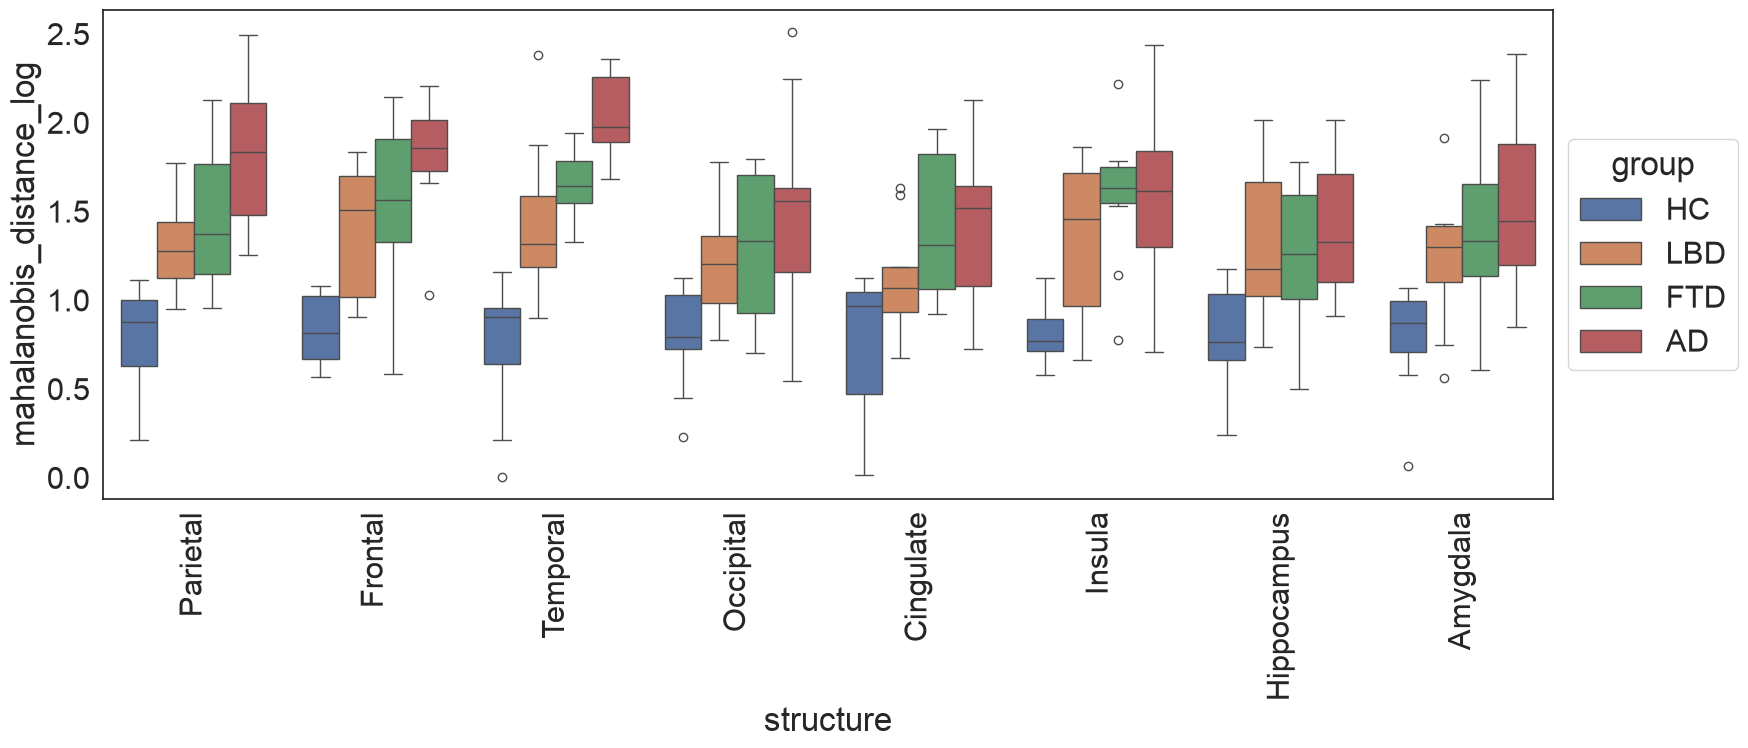

In [28]:
sns.reset_defaults()
plt.figure(figsize=(18, 8)) 
sns.set_theme(style="white", font_scale=2)
plt.rcParams['svg.fonttype'] = 'none'
ax = sns.boxplot(data=df_brain_grouped_mahallanobis, x='structure', y="mahalanobis_distance_log", hue="group", order=structure_order)
sns.move_legend(ax, 'center left' , bbox_to_anchor=(1, 0.5))
# Code to adjust layout and show the plot
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90) 

plt.tight_layout()
#plt.savefig('../static/fig_boxplotMahaMetrics.svg')

plt.show()

In [29]:
# Run ANCOVA test for each structure and MhD, controlling for age + sex
df_brain_grouped_ancova = st.ancova_tests(df_brain_grouped_mahallanobis, ['mahalanobis_distance_log'], structures, summary_ancovaAssumptions, covar='age + sex')
# Perform multiple-comparison correction on the group variable results of the ANCOVA tests
df_brain_grouped_ancova_Pcorrected = st.post_ancova_correctMultipleComparison(df_brain_grouped_ancova, mc_method='fdr_by', mc_alpha=mc_alpha)

Total results collected: 32


In [30]:
#| label: notebook_table_MhD_ancovaResults_significant

cols = ["structure", "metric", "F value", "Df_residual",
        "Omega2_partial", "CI_low.y", "pvals_adj", "level",
        "violated_terms"
        ]

df_sig_maha = (
    df_brain_grouped_ancova_Pcorrected
    #.query("pvals_adj < @mc_alpha")
    [cols]
    .rename(columns={
        "F value":        "F(3, df_err)",
        "Df_residual":    "df_err",
        "Omega2_partial": "ω²ₚ",
        "CI_low.y":       "95% CI lower",
        "pvals_adj":      "p_adj",
        "violated_terms": "Interaction included"
    })
    .sort_values(["structure", "metric"])
    #.round(4)
    .copy()
).reset_index(drop=True)

df_sig_maha["Interaction included"] = df_sig_maha["Interaction included"].replace("", "—")

st.display_table(st.format_table(df_sig_maha.sort_values(by='ω²ₚ', ascending=False), two_decimals=["F(3, df_err)", "ω²ₚ", "95% CI lower"], p_values=["p_adj"]))

ROI,Metric,"F(3, df_err)",df_err,ω²ₚ,95% CI lower,p_adj,Interaction included
Temporal,log MhD,35.76,41,0.70,0.56,3.5e-10,—
Frontal,log MhD,18.58,41,0.55,0.36,9.9e-07,—
Parietal,log MhD,17.83,41,0.54,0.34,1.1e-06,—
Insula,log MhD,10.99,41,0.43,0.22,0.0001,—
Cingulate,log MhD,7.92,41,0.34,0.12,0.0012,—
Amygdala,log MhD,6.29,41,0.30,0.09,0.0047,—
Hippocampus,log MhD,4.72,41,0.30,0.09,0.0174,—
Occipital,log MhD,5.36,41,0.26,0.05,0.0103,—


### ROIs

In [31]:
# Run ANCOVA test for each structure and metric, controlling for age + sex
df_brain_grouped_ancova = st.ancova_tests(df_brain_grouped, metrics, structures, summary_ancovaAssumptions, covar='age + sex')
# Perform multiple-comparison correction on the group variable results of the ANCOVA tests
df_brain_grouped_ancova_Pcorrected = st.post_ancova_correctMultipleComparison(df_brain_grouped_ancova, mc_method='fdr_by', mc_alpha=mc_alpha)

Total results collected: 192


Check homogeneity of regression slopes to asses Ancova assumpsions

In [32]:
summary_ancovaAssumptions, raw = aa.ancova_assumption_tests(df_brain_grouped, metrics, structures, covar='age + sex')

Total results collected: 288 rows across 48 structure/metric combinations


Total results collected: 48


Total results collected: 96
Total assumption checks run: 240 | Violations flagged: 20


In [33]:
#| label: notebook_table_ancova_violations
assumption_names = {
    "homogeneity_of_slopes": "Homogeneity of regression slopes",
    "normality_of_residuals": "Normality of residuals",
    "homogeneity_of_variance": "Homogeneity of variance",
}
test_names = {
    "group:age": "group × age interaction",
    "group:sex": "group × sex interaction",
    "shapiro_wilk": "Shapiro–Wilk",
    "group": "Levene",
}

df_violations = (
    summary_ancovaAssumptions
    .query("flag_violated == True")
    .drop(columns="flag_violated")
    .assign(test_name=lambda d: d["test_name"].replace(assumption_names),
            term=lambda d: d["term"].replace(test_names))
    .reset_index(drop=True)
)

st.display_table(st.format_table(df_violations, p_values=["p_value"]))

ROI,Metric,Assumption,Test,p
Frontal,FA,Homogeneity of regression slopes,group × age interaction,0.0444
Frontal,MD,Homogeneity of regression slopes,group × age interaction,0.0035
Frontal,µFA,Homogeneity of regression slopes,group × age interaction,0.0044
Frontal,Ki,Homogeneity of regression slopes,group × age interaction,0.0152
Temporal,µFA,Homogeneity of regression slopes,group × age interaction,0.0278
Temporal,Ki,Homogeneity of regression slopes,group × age interaction,0.0098
Occipital,Ki,Homogeneity of regression slopes,group × age interaction,0.0229
Occipital,MTsat,Homogeneity of regression slopes,group × sex interaction,0.0482
Cingulate,MD,Homogeneity of regression slopes,group × age interaction,0.0014
Cingulate,µFA,Homogeneity of regression slopes,group × age interaction,0.0040


In [34]:
# Uncomment to visually inspect the normality assumption for violated cases
#fig = aa.plot_normality_diagnostics(df, raw['normality'])
#fig

In [35]:
# Run ANCOVA test for each structure and metric, controlling for age + sex
df_brain_grouped_ancova = st.ancova_tests(df_brain_grouped_mahallanobis, metrics, structures, summary_ancovaAssumptions, covar='age + sex')
# Perform multiple-comparison correction on the group variable results of the ANCOVA tests
df_brain_grouped_ancova_Pcorrected = st.post_ancova_correctMultipleComparison(df_brain_grouped_ancova, mc_method='fdr_by', mc_alpha=mc_alpha)

Total results collected: 206


In [36]:
#| label: notebook_table_ancovaResults_significant

cols = ["structure", "metric", "F value", "Df_residual",
        "Omega2_partial", "CI_low.y", "pvals_adj", "level",
        "violated_terms"
        ]

df_sig = (
    df_brain_grouped_ancova_Pcorrected
    .query("pvals_adj < @mc_alpha")
    [cols]
    .rename(columns={
        "F value":        "F(3, df_err)",
        "Df_residual":    "df_err",
        "Omega2_partial": "ω²ₚ",
        "CI_low.y":       "95% CI lower",
        "pvals_adj":      "p_adj",
        "violated_terms": "Interaction included"
    })
    .sort_values(["structure", "metric"])
).reset_index(drop=True)

df_sig["Interaction included"] = df_sig["Interaction included"].replace("", "—")

st.display_table(st.format_table(df_sig, two_decimals=["F(3, df_err)", "ω²ₚ", "95% CI lower"], p_values=["p_adj"]))

ROI,Metric,"F(3, df_err)",df_err,ω²ₚ,95% CI lower,p_adj,Interaction included
Amygdala,MD,5.36,44,0.24,0.05,0.0374,—
Amygdala,MTsat,6.24,41,0.36,0.14,0.0263,—
Amygdala,Normalized volume,5.41,44,0.23,0.04,0.0374,—
Cingulate,FA,5.68,44,0.30,0.10,0.0342,—
Cingulate,MD,8.30,41,0.34,0.12,0.0085,group:age
Frontal,MD,9.92,41,0.35,0.14,0.0035,group:age
Frontal,µFA,5.41,41,0.20,0.02,0.0374,group:age
Hippocampus,MD,5.60,44,0.26,0.07,0.0346,—
Hippocampus,MTsat,5.90,41,0.34,0.12,0.0316,—
Hippocampus,µFA,7.47,44,0.34,0.13,0.0102,—


In [37]:
df_brain_grouped_ancova_posthoc = st.posthoc_eem_tests(df_brain_grouped, df_brain_grouped_ancova_Pcorrected, summary_ancovaAssumptions, mc_alpha=0.05, covar = 'age + sex')

In [38]:
#| label: notebook_table_posthocResults_significant
cols = [
    "structure", "metric", "contrast",
    "df", "t_value",
    "hedges_g", "hedges_g_low", "hedges_g_high",
    "p_holm", "level"
]
df_brain_grouped_ancova_posthoc_sig = (
    df_brain_grouped_ancova_posthoc
    .query("p_holm < @mc_alpha")
    [cols]
    .rename(columns={
        "df":            "df_err",
        "t_value":       "t",
        "hedges_g":      "g",
        "hedges_g_low":  "g CI low",
        "hedges_g_high": "g CI high",
        "p_holm":        "p (Holm)"
    })
    .sort_values(["structure", "metric", "contrast"])
    .reset_index(drop=True)
)

st.display_table(st.format_table(df_brain_grouped_ancova_posthoc_sig, two_decimals=["t", "g", "g CI low", "g CI high"], p_values=["p (Holm)"]))

ROI,Metric,Contrast,df_err,t,g,g CI low,g CI high,p (Holm)
Amygdala,MD,AD - HC,44,3.35,1.31,0.52,2.09,0.0017
Amygdala,MD,AD - LBD,44,2.49,1.05,0.20,1.91,0.0167
Amygdala,MD,FTD - HC,44,2.82,1.11,0.32,1.90,0.0071
Amygdala,MTsat,AD - HC,41,-3.72,-1.49,-2.30,-0.68,0.0006
Amygdala,MTsat,AD - LBD,41,-2.89,-1.29,-2.19,-0.39,0.0061
Amygdala,MTsat,FTD - HC,41,-2.72,-1.08,-1.89,-0.28,0.0095
Amygdala,Normalized volume,AD - HC,44,-3.24,-1.27,-2.05,-0.48,0.0023
Amygdala,Normalized volume,FTD - HC,44,-3.35,-1.31,-2.10,-0.52,0.0017
Cingulate,FA,AD - FTD,44,3.96,1.56,0.77,2.35,0.0003
Cingulate,FA,AD - HC,44,2.92,1.14,0.35,1.93,0.0055


In [39]:
#| label: notebook_fig_posthocResults_significant

pivot_order = ['AD - HC', 'FTD - HC', 'LBD - HC', 'AD - LBD', 'FTD - LBD', 'AD - FTD'] 

pivot = (
    df_brain_grouped_ancova_posthoc_sig
    .pivot_table(index=['structure', 'metric'],
                 columns='contrast',
                 values="g",
                 aggfunc='first')
    .reindex(columns=pivot_order)
)
# contrasts that did not survive Holm correction stay NaN: drawn as blank cells, not as g = 0

# flatten the multiindex row labels into a single string per row for display
row_labels = [f"{s} — {st.metric_name(m)}" for s, m in pivot.index]

fig = px.imshow(
    pivot.values,
    x=pivot.columns.tolist(),
    y=row_labels,
    color_continuous_scale='RdBu_r',
    color_continuous_midpoint=0,
    aspect='auto',
    labels=dict(color="Hedges' g"),
)

fig.update_traces(
    text=[["" if np.isnan(v) else f"{v:.2f}" for v in row] for row in pivot.values],
    texttemplate="%{text}",
    hovertemplate="%{y}<br>%{x}<br>Hedges' g = %{z:.2f}<extra></extra>",
)

fig.update_layout(
    plot_bgcolor="white",
    title="Pairwise group differences",
    width=700,
    height=900,
    margin=dict(l=200, r=60, t=60, b=60),  # extra left margin for long row labels
)

fig

In [40]:
#| label: notebook_figStatic_posthocResults_significant
if create_Static_figures:
    helpers.static_theme(style="white")
    pivot = (
        df_brain_grouped_ancova_posthoc_sig
        .pivot_table(index=['structure', 'metric'], columns='contrast', values="g", aggfunc='first')
        .reindex(columns=pivot_order)
    )
    pivot.index = [f"{s} — {st.metric_name(m)}" for s, m in pivot.index]

    fig, ax = plt.subplots(figsize=(helpers.TEXT_WIDTH_IN, 5.2))
    # contrasts that did not survive Holm correction (NaN) are left blank, as in the interactive figure
    sns.heatmap(pivot, mask=pivot.isna(), annot=True, fmt='.2f', annot_kws={"size": 7}, center=0, cmap='RdBu_r',
                linewidths=0.5, linecolor="white", ax=ax, cbar_kws={'label': "Hedges' g"})
    ax.set_xlabel("Contrast")
    ax.set_ylabel("ROI — metric")
    ax.tick_params(length=0)
    fig.tight_layout()
    helpers.save_static_figure(fig, "fig_posthocResults_significant")
    plt.close(fig)
    sns.set_theme()